# Regresión lineal en GPU con Numba CUDA y distribuida con Dask

Proyecto final de Computación Paralela y Distribuida. Una regresión lineal por descenso de gradiente sobre 100.000 filas y 1.000 variables se resuelve de tres formas: en CPU con NumPy, en GPU con kernels propios de Numba CUDA y con Dask, repartiendo los datos en bloques entre cuatro workers que usan esos mismos kernels. Las tres se verifican contra la solución exacta de mínimos cuadrados y se miden sus tiempos, separando el costo de mover los datos.

Se ejecuta en Colab con GPU (*Entorno de ejecución → Cambiar tipo de entorno → GPU T4*).

Autores: Santiago Castellanos, Catalina Gutiérrez y Camilo Millán.

In [1]:
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numba import cuda, float32

SIMULADOR = os.environ.get("NUMBA_ENABLE_CUDASIM") == "1"  # solo para probar sin GPU
if not SIMULADOR and not cuda.is_available():
    raise RuntimeError("Este notebook necesita una GPU: Entorno de ejecución → Cambiar tipo de entorno → GPU T4.")

if SIMULADOR:
    N, P, ITERACIONES, FILAS_POR_BLOQUE = 256, 16, 3, 64
    HILOS_MSE, BLOQUES_MSE, HILOS_2D = 32, 2, (4, 4)
else:
    N, P, ITERACIONES, FILAS_POR_BLOQUE = 100_000, 1_000, 50, 20_000
    HILOS_MSE, BLOQUES_MSE, HILOS_2D = 1024, 32 * 40, (32, 32)
TASA = 0.1
rng = np.random.default_rng(36)

print(f"Núcleos de CPU disponibles: {os.cpu_count()}")
if not SIMULADOR:
    cuda.detect()

Núcleos de CPU disponibles: 2
Found 1 CUDA devices
id 0                Tesla T4                              [SUPPORTED]
                      Compute Capability: 7.5
                           PCI Device ID: 4
                              PCI Bus ID: 0
                                    UUID: GPU-4b416a72-19f5-70fb-70bb-1c8364e1020c
                                Watchdog: Disabled
             FP32/FP64 Performance Ratio: 32
                            FP16 Support: Yes
                            BF16 Support: No
                             FP8 Support: No
Summary:
	1/1 devices are supported


## Datos

Datos sintéticos: $Y = X\beta + \varepsilon$, con $X$ y $\beta$ uniformes en $[0, 1)$ y ruido $\varepsilon$ uniforme en $[0, 1)$. $X$ e $Y$ se estandarizan antes de entrenar.

Como el ruido es parte de los datos, ningún modelo lineal puede bajar el error de cierto piso. La referencia es la **solución exacta** de mínimos cuadrados: el descenso de gradiente está bien implementado si su MSE se acerca al de esa solución y sus coeficientes se parecen a los suyos.

In [2]:
X = rng.random((N, P))
beta_real = rng.random((P, 1))
Y = X @ beta_real + rng.random((N, 1))

X = (X - X.mean(axis=0)) / X.std(axis=0)
Y = (Y - Y.mean()) / Y.std()

X32 = np.ascontiguousarray(X, dtype=np.float32)
Y32 = np.ascontiguousarray(Y, dtype=np.float32)

beta_exacto, *_ = np.linalg.lstsq(X, Y, rcond=None)
mse_exacto = float(np.mean((Y - X @ beta_exacto) ** 2))
print(f"X: {X32.shape}, {X32.nbytes / 1e6:,.0f} MB en float32")
print(f"MSE de la solución exacta: {mse_exacto:.6f}")

X: (100000, 1000), 400 MB en float32
MSE de la solución exacta: 0.002954


## Kernels CUDA

- **Producto matricial:** cada hilo calcula un elemento de la matriz resultado recorriendo una fila de `a` y una columna de `b`. Es la versión directa, sin memoria compartida.
- **Error cuadrático:** cada hilo acumula los cuadrados de varias posiciones y cada bloque suma sus hilos en memoria compartida; la suma final de los bloques se hace en la CPU.

El gradiente del MSE es $\nabla = \frac{2}{n} X^\top (X\beta - Y)$. En GPU se usa la forma $\frac{2}{n}\left(X^\top (X\beta) - X^\top Y\right)$: $X^\top Y$ no cambia entre iteraciones y se calcula una sola vez, y $X$ y $X^\top$ se copian a la GPU una sola vez y se reutilizan en todo el entrenamiento.

In [3]:
@cuda.jit
def producto_kernel(a, b, c):
    fila, col = cuda.grid(2)
    if fila < c.shape[0] and col < c.shape[1]:
        acumulado = 0.0
        for k in range(a.shape[1]):
            acumulado += a[fila, k] * b[k, col]
        c[fila, col] = acumulado


@cuda.jit
def error_cuadratico_kernel(y, y_pred, parciales):
    inicio = cuda.grid(1)
    paso = cuda.blockDim.x * cuda.gridDim.x
    suma_hilo = 0.0
    for i in range(inicio, y.shape[0], paso):
        diferencia = y[i, 0] - y_pred[i, 0]
        suma_hilo += diferencia * diferencia

    compartido = cuda.shared.array(HILOS_MSE, float32)
    hilo = cuda.threadIdx.x
    compartido[hilo] = suma_hilo
    cuda.syncthreads()
    if hilo == 0:
        suma_bloque = 0.0
        for j in range(cuda.blockDim.x):
            suma_bloque += compartido[j]
        parciales[cuda.blockIdx.x] = suma_bloque


def producto_gpu(a_d, b_d, c_d):
    "c = a @ b con arreglos que ya están en la GPU."
    bloques = ((c_d.shape[0] + HILOS_2D[0] - 1) // HILOS_2D[0],
               (c_d.shape[1] + HILOS_2D[1] - 1) // HILOS_2D[1])
    producto_kernel[bloques, HILOS_2D](a_d, b_d, c_d)


def mse_gpu(y_d, pred_d, parciales_d):
    error_cuadratico_kernel[BLOQUES_MSE, HILOS_MSE](y_d, pred_d, parciales_d)
    return float(parciales_d.copy_to_host().sum()) / y_d.shape[0]

## Verificación de los kernels

Se comparan con NumPy usando un $\beta$ aleatorio (con $\beta = 0$ cualquier producto da cero y la prueba no comprueba nada). La GPU trabaja en float32, así que la comparación usa el **error relativo**: una tolerancia absoluta fija no tiene sentido cuando los valores son del orden de miles.

In [4]:
def error_relativo(a, b):
    return float(np.max(np.abs(a - b)) / np.max(np.abs(b)))

beta_prueba = rng.standard_normal((P, 1)).astype(np.float32)
X_d, Xt_d, Y_d = cuda.to_device(X32), cuda.to_device(np.ascontiguousarray(X32.T)), cuda.to_device(Y32)
beta_d = cuda.to_device(beta_prueba)
pred_d = cuda.device_array((N, 1), dtype=np.float32)
grad_d = cuda.device_array((P, 1), dtype=np.float32)
xty_d = cuda.device_array((P, 1), dtype=np.float32)
parciales_d = cuda.device_array(BLOQUES_MSE, dtype=np.float32)

producto_gpu(X_d, beta_d, pred_d)
pred_cpu = X32.astype(np.float64) @ beta_prueba.astype(np.float64)
producto_gpu(Xt_d, pred_d, grad_d)
producto_gpu(Xt_d, Y_d, xty_d)
grad_gpu = 2 / N * (grad_d.copy_to_host() - xty_d.copy_to_host())
grad_cpu = 2 / N * (X.T @ (pred_cpu - Y))
assert grad_gpu.shape == grad_cpu.shape == (P, 1)

comprobaciones = pd.DataFrame({
    "Operación": ["Producto Xβ", "Gradiente", "MSE"],
    "Error relativo GPU vs. CPU": [
        error_relativo(pred_d.copy_to_host(), pred_cpu),
        error_relativo(grad_gpu, grad_cpu),
        abs(mse_gpu(Y_d, pred_d, parciales_d) - float(np.mean((Y - pred_cpu) ** 2))) / float(np.mean((Y - pred_cpu) ** 2)),
    ],
})
assert (comprobaciones["Error relativo GPU vs. CPU"] < 1e-3).all()
comprobaciones.style.format({"Error relativo GPU vs. CPU": "{:.1e}"}).hide(axis="index")

/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 32 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


Operación,Error relativo GPU vs. CPU
Producto Xβ,4.5e-08
Gradiente,7.9e-08
MSE,8.8e-08


## Entrenamiento

Las tres versiones hacen exactamente el mismo descenso de gradiente: $\beta$ empieza en cero, tasa de aprendizaje 0,1, gradiente promedio y el mismo número de iteraciones. En cada iteración se registra el MSE antes de actualizar $\beta$.

Los tiempos se toman después de una corrida de calentamiento, para no contar la compilación de los kernels, y en GPU se sincroniza antes de leer el reloj, porque los kernels se lanzan de forma asíncrona.

In [5]:
def entrenar_cpu(X, Y):
    n = X.shape[0]
    beta = np.zeros((X.shape[1], 1), dtype=X.dtype)
    historial = []
    for _ in range(ITERACIONES):
        residuo = X @ beta - Y
        historial.append(float(np.mean(residuo ** 2)))
        beta -= TASA * (2 / n) * (X.T @ residuo)
    return beta, historial

inicio = time.perf_counter()
beta_cpu, historial_cpu = entrenar_cpu(X32, Y32)
tiempo_cpu = time.perf_counter() - inicio
print(f"CPU: {tiempo_cpu:.2f} s")

CPU: 3.28 s


In [6]:
def copiar_a_gpu():
    "Copia X, su transpuesta e Y a la GPU y reserva los arreglos de trabajo."
    arreglos = {
        "X": cuda.to_device(X32),
        "Xt": cuda.to_device(np.ascontiguousarray(X32.T)),
        "Y": cuda.to_device(Y32),
        "pred": cuda.device_array((N, 1), dtype=np.float32),
        "xtxb": cuda.device_array((P, 1), dtype=np.float32),
        "xty": cuda.device_array((P, 1), dtype=np.float32),
        "parciales": cuda.device_array(BLOQUES_MSE, dtype=np.float32),
    }
    cuda.synchronize()
    return arreglos


def entrenar_gpu(g, iteraciones=ITERACIONES):
    producto_gpu(g["Xt"], g["Y"], g["xty"])
    xty = g["xty"].copy_to_host()
    beta = np.zeros((P, 1), dtype=np.float32)
    historial = []
    for _ in range(iteraciones):
        beta_d = cuda.to_device(beta)
        producto_gpu(g["X"], beta_d, g["pred"])
        historial.append(mse_gpu(g["Y"], g["pred"], g["parciales"]))
        producto_gpu(g["Xt"], g["pred"], g["xtxb"])
        beta -= TASA * (2 / N) * (g["xtxb"].copy_to_host() - xty)
    cuda.synchronize()
    return beta, historial


del X_d, Xt_d, Y_d, beta_d, pred_d, grad_d, xty_d, parciales_d
inicio = time.perf_counter()
gpu = copiar_a_gpu()
transferencia_gpu = time.perf_counter() - inicio

entrenar_gpu(gpu, iteraciones=1)  # calentamiento
inicio = time.perf_counter()
beta_gpu, historial_gpu = entrenar_gpu(gpu)
tiempo_gpu = time.perf_counter() - inicio
print(f"GPU: copia inicial {transferencia_gpu:.2f} s, entrenamiento {tiempo_gpu:.2f} s")

GPU: copia inicial 0.69 s, entrenamiento 1.20 s


### Con Dask

$X$ se parte en bloques de filas y cada bloque se envía una sola vez a uno de los cuatro workers, que lo guarda en su memoria. En cada iteración, cada worker calcula con los kernels de GPU su parte del gradiente, $X_b^\top (X_b\beta - Y_b)$, y su suma de errores cuadráticos; el proceso principal suma las partes, actualiza $\beta$ y lo envía de nuevo.

Los cuatro workers comparten la única GPU del entorno y cada uno copia su bloque a la GPU en cada iteración, porque la memoria de un worker es la de la CPU. Esta parte mide cuánto cuesta esa organización frente a un solo proceso.

In [7]:
import logging
from dask.distributed import Client, LocalCluster

logging.getLogger("distributed").setLevel(logging.ERROR)

def parte_del_gradiente(bloque, beta):
    Xb, Yb = bloque
    Xb_d = cuda.to_device(Xb)
    pred_d = cuda.device_array((Xb.shape[0], 1), dtype=np.float32)
    producto_gpu(Xb_d, cuda.to_device(beta), pred_d)
    residuo = pred_d.copy_to_host() - Yb
    gradiente_d = cuda.device_array((1, Xb.shape[1]), dtype=np.float32)
    producto_gpu(cuda.to_device(np.ascontiguousarray(residuo.T)), Xb_d, gradiente_d)
    return gradiente_d.copy_to_host().T, float(np.sum(residuo.astype(np.float64) ** 2))


def entrenar_dask(client, bloques, iteraciones=ITERACIONES):
    beta = np.zeros((P, 1), dtype=np.float32)
    historial = []
    for _ in range(iteraciones):
        partes = client.gather([client.submit(parte_del_gradiente, b, beta, pure=False) for b in bloques])
        gradiente = sum(g for g, _ in partes)
        historial.append(sum(s for _, s in partes) / N)
        beta -= TASA * (2 / N) * gradiente
    return beta, historial


cluster = LocalCluster(n_workers=4, threads_per_worker=1, processes=True, dashboard_address=None,
                       silence_logs=logging.ERROR)
client = Client(cluster)

inicio = time.perf_counter()
bloques = client.scatter([(X32[i:i + FILAS_POR_BLOQUE], Y32[i:i + FILAS_POR_BLOQUE])
                          for i in range(0, N, FILAS_POR_BLOQUE)])
client.gather(client.map(len, bloques))  # espera a que los bloques estén en los workers
transferencia_dask = time.perf_counter() - inicio

entrenar_dask(client, bloques, iteraciones=1)  # calentamiento: compila los kernels en cada worker
inicio = time.perf_counter()
beta_dask, historial_dask = entrenar_dask(client, bloques)
tiempo_dask = time.perf_counter() - inicio
print(f"Dask: {len(bloques)} bloques en 4 workers; reparto {transferencia_dask:.2f} s, entrenamiento {tiempo_dask:.2f} s")

client.close()
cluster.close()

Dask: 5 bloques en 4 workers; reparto 0.67 s, entrenamiento 36.03 s


## Resultados

In [8]:
def distancia(beta):
    return float(np.linalg.norm(beta - beta_exacto) / np.linalg.norm(beta_exacto))

def mse_final(beta):
    return float(np.mean((Y - X @ beta.astype(np.float64)) ** 2))

resultados = pd.DataFrame({
    "Versión": ["CPU (NumPy)", "GPU (kernels Numba)", "Dask + GPU (4 workers)"],
    "Copia o reparto inicial (s)": [0.0, transferencia_gpu, transferencia_dask],
    "Entrenamiento (s)": [tiempo_cpu, tiempo_gpu, tiempo_dask],
    "Por iteración (ms)": [t / ITERACIONES * 1000 for t in (tiempo_cpu, tiempo_gpu, tiempo_dask)],
    "MSE final": [mse_final(b) for b in (beta_cpu, beta_gpu, beta_dask)],
    "Distancia a la solución exacta": [distancia(b) for b in (beta_cpu, beta_gpu, beta_dask)],
})
resultados["Aceleración frente a CPU"] = tiempo_cpu / resultados["Entrenamiento (s)"]
print(f"MSE de la solución exacta: {mse_exacto:.6f}")
resultados.style.format({
    "Copia o reparto inicial (s)": "{:.2f}", "Entrenamiento (s)": "{:.2f}", "Por iteración (ms)": "{:.1f}",
    "MSE final": "{:.6f}", "Distancia a la solución exacta": "{:.4f}", "Aceleración frente a CPU": "{:.2f}×",
}).hide(axis="index")

MSE de la solución exacta: 0.002954


Versión,Copia o reparto inicial (s),Entrenamiento (s),Por iteración (ms),MSE final,Distancia a la solución exacta,Aceleración frente a CPU
CPU (NumPy),0.00,3.28,65.6,0.002954,0.0000,1.00×
GPU (kernels Numba),0.69,1.20,24.0,0.002954,0.0000,2.73×
Dask + GPU (4 workers),0.67,36.03,720.6,0.002954,0.0000,0.09×


In [9]:
# Las tres versiones deben recorrer la misma trayectoria: comparan el MSE iteración por iteración.
for nombre, historial in (("GPU", historial_gpu), ("Dask", historial_dask)):
    diferencia = np.max(np.abs(np.array(historial) - np.array(historial_cpu)) / np.array(historial_cpu))
    print(f"{nombre}: diferencia relativa máxima con la CPU en el MSE por iteración = {diferencia:.1e}")
    assert diferencia < 1e-3

GPU: diferencia relativa máxima con la CPU en el MSE por iteración = 2.6e-07
Dask: diferencia relativa máxima con la CPU en el MSE por iteración = 2.0e-07


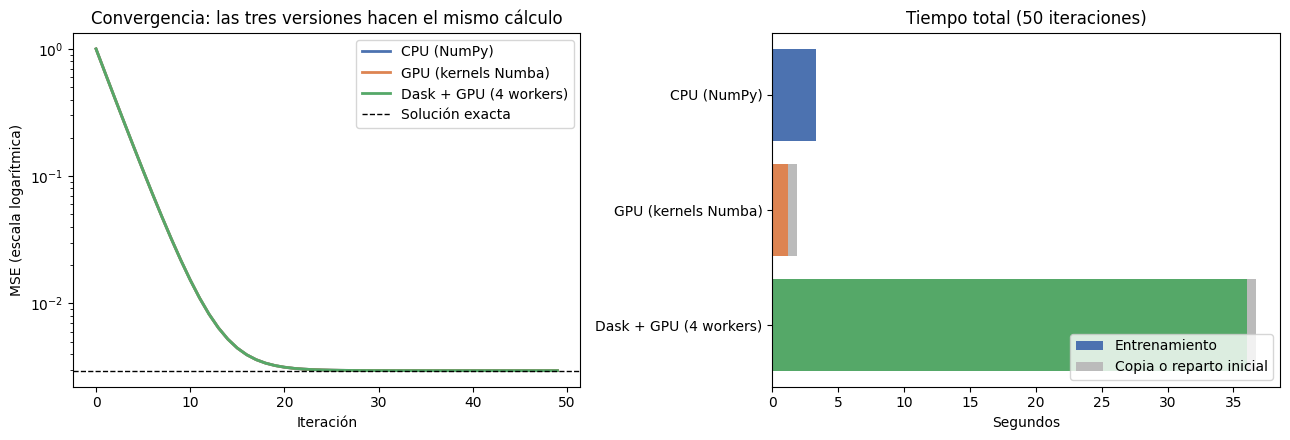

In [10]:
colores = {"CPU (NumPy)": "#4C72B0", "GPU (kernels Numba)": "#DD8452", "Dask + GPU (4 workers)": "#55A868"}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

for nombre, historial in zip(colores, (historial_cpu, historial_gpu, historial_dask)):
    ax1.plot(historial, label=nombre, color=colores[nombre], linewidth=2)
ax1.axhline(mse_exacto, color="black", linestyle="--", linewidth=1, label="Solución exacta")
ax1.set_yscale("log")
ax1.set_xlabel("Iteración")
ax1.set_ylabel("MSE (escala logarítmica)")
ax1.set_title("Convergencia: las tres versiones hacen el mismo cálculo")
ax1.legend()

nombres = list(colores)
copia = resultados["Copia o reparto inicial (s)"].to_numpy()
entrenamiento = resultados["Entrenamiento (s)"].to_numpy()
ax2.barh(nombres, entrenamiento, color=[colores[n] for n in nombres], label="Entrenamiento")
ax2.barh(nombres, copia, left=entrenamiento, color="#BBBBBB", label="Copia o reparto inicial")
ax2.invert_yaxis()
ax2.set_xlabel("Segundos")
ax2.set_title(f"Tiempo total ({ITERACIONES} iteraciones)")
ax2.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [11]:
print(f"GPU frente a CPU: {tiempo_cpu / tiempo_gpu:.1f} veces más rápida en el entrenamiento")
print(f"Copia inicial a la GPU: {transferencia_gpu / tiempo_gpu:.0%} del tiempo de entrenamiento en GPU")
print(f"Dask + GPU frente a CPU: {tiempo_dask / tiempo_cpu:.1f} veces más lento")
print(f"Dask + GPU frente a GPU en un solo proceso: {tiempo_dask / tiempo_gpu:.0f} veces más lento")

GPU frente a CPU: 2.7 veces más rápida en el entrenamiento
Copia inicial a la GPU: 58% del tiempo de entrenamiento en GPU
Dask + GPU frente a CPU: 11.0 veces más lento
Dask + GPU frente a GPU en un solo proceso: 30 veces más lento


## Lectura

- **Las tres versiones calculan lo mismo y llegan a la solución.** Siguen la misma trayectoria de error iteración por iteración y terminan en el MSE de la solución exacta de mínimos cuadrados. Los kernels y el descenso de gradiente están bien implementados, y la precisión de float32 alcanza para este problema.
- **La GPU acelera, pero poco para lo que podría.** Con $X$ ya en la memoria de la GPU, los kernels propios entrenan más rápido que NumPy en CPU. El kernel de producto es el directo y está mal aprovechado en este problema: al calcular $X\beta$ el resultado tiene una sola columna, así que en cada bloque de 32 × 32 hilos solo trabajan los 32 de esa columna; y $X^\top(X\beta)$ produce apenas 1.000 resultados, cada uno con un recorrido de 100.000 elementos. Una configuración de hilos de una dimensión o una biblioteca como cuBLAS aprovecharían mejor la tarjeta.
- **Mover los datos cuesta tanto como calcular.** Copiar $X$ y su transpuesta a la GPU toma una fracción importante del tiempo de entrenamiento. Por eso se copian una sola vez y los kernels trabajan sobre arreglos que ya están en la tarjeta; si la copia se repitiera en cada llamada, la ventaja de la GPU desaparecería.
- **Dask, en una sola máquina, solo suma costo.** Es la versión más lenta, por mucho. En cada iteración cada worker vuelve a copiar su bloque a la GPU (en total, todo $X$), los cuatro procesos comparten una sola GPU y los pocos núcleos del entorno, y cada iteración exige serializar, enviar y reunir resultados entre procesos. Repartir el trabajo con Dask tiene sentido cuando los datos no caben en la memoria de una máquina o hay varias máquinas o varias GPU; con 400 MB en un solo equipo, un proceso que deja los datos en la GPU es la mejor opción.